# guarded event control: Comparison with published methods

**Level:** 3 **Prerequisites:** Fast event control level 1 **Reading time:** 25 minutes

**Question:** How does a fresh strongest learned baseline compare with the guarded fast policies on this matched C01 observation?

## Objectives

This lesson investigates the question: How does a fresh strongest learned baseline compare with the guarded fast policies on this matched C01 observation?

## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata;

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
The notebook reads committed product artifacts. Owner: Neuraxis. Repository: https://github.com/fsantibanezleal/CAOS_Neuraxis. License: Apache-2.0. The JSON is a first-party, frozen experiment artifact; no external benchmark data are redistributed in this notebook;

This notebook reads `data/derived/index.json` and the listed trace artifacts. The method run uses an isolated Reflexmesh case workspace; For learned methods, fetch the exact public release assets with `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder; The release manifest verifies asset hashes. Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model;

Artifacts for this lesson:

- `data/derived/index.json` - `data/derived/episodes/M01-C01-nominal-40000; - `data/derived/episodes/M02-C01-nominal-40000;json`

## Method

The comparison is framed against typed fast decisions, arbitration between model-free and model-based control, and asynchronous code-plus-language-model agents. These sources establish prior designs and experimental questions, not independent evidence that Neuraxis is biologically System One or that a typed action broker is novel. The empirical reference here is M04 on the same case, while M01 remains the strongest measured core rule baseline. The distinction between external prior art and an internal benchmark winner is deliberate. A meaningful stress test changes event timing or candidate availability while preserving the task contract, then checks whether both controllers retain the postcondition rather than merely selecting the same first action. The trace should be read as an observation, an admissible set, a selected action and an independent oracle result; collapsing those fields into one success label hides where control authority came from. A one-case agreement is evidence of local consistency only; robustness requires independently varied seeds and perturbations that can expose stale-state handling, missing candidates and unauthorized effects. A useful extension changes one event ordering at a time, preserves the case oracle, and records which transition caused divergence so the controller's response can be reproduced.

### guarded event control · level 3 | Verify the audit and each trace's bytes before interpreting outcomes.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M01', 'M02', 'M04']
sample_case, seed = 'C01', 40000
evidence = load_lesson_evidence(
    ROOT, topic='01-fast-event-control', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))


Hash-verified records: 3 | case variants: 18


### Compare methods across variants: guarded event control

Across variants, distinguish a fast admissible response from a policy preference; an action that is cheap but stale is still invalid.

### guarded event control · level 3 | Execute the released policies and compare the run

### guarded event control · level 3 | Compare the full sequence, not only the first action

### guarded event control · level 3 | Recompute per-variant outcomes from every trace in the case

In [3]:
# Read every seed for the selected case and keep each failed episode in the denominator.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "successes=",
        sum(values),
        "episodes=",
        len(values),
        "rate=",
        round(sum(values) / len(values), 3),
    )


M01 boundary successes= 10 episodes= 10 rate= 1.0
M01 delayed_observation successes= 10 episodes= 10 rate= 1.0
M01 duplicate_event successes= 10 episodes= 10 rate= 1.0
M01 nominal successes= 10 episodes= 10 rate= 1.0
M01 stale_conflict successes= 10 episodes= 10 rate= 1.0
M01 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M02 boundary successes= 10 episodes= 10 rate= 1.0
M02 delayed_observation successes= 10 episodes= 10 rate= 1.0
M02 duplicate_event successes= 10 episodes= 10 rate= 1.0
M02 nominal successes= 10 episodes= 10 rate= 1.0
M02 stale_conflict successes= 10 episodes= 10 rate= 1.0
M02 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M04 boundary successes= 10 episodes= 10 rate= 1.0
M04 delayed_observation successes= 10 episodes= 10 rate= 1.0
M04 duplicate_event successes= 10 episodes= 10 rate= 1.0
M04 nominal successes= 10 episodes= 10 rate= 1.0
M04 stale_conflict successes= 10 episodes= 10 rate= 1.0
M04 unavailable_dependency successes= 10 episodes= 10

### Plot the variant stress without pooling families

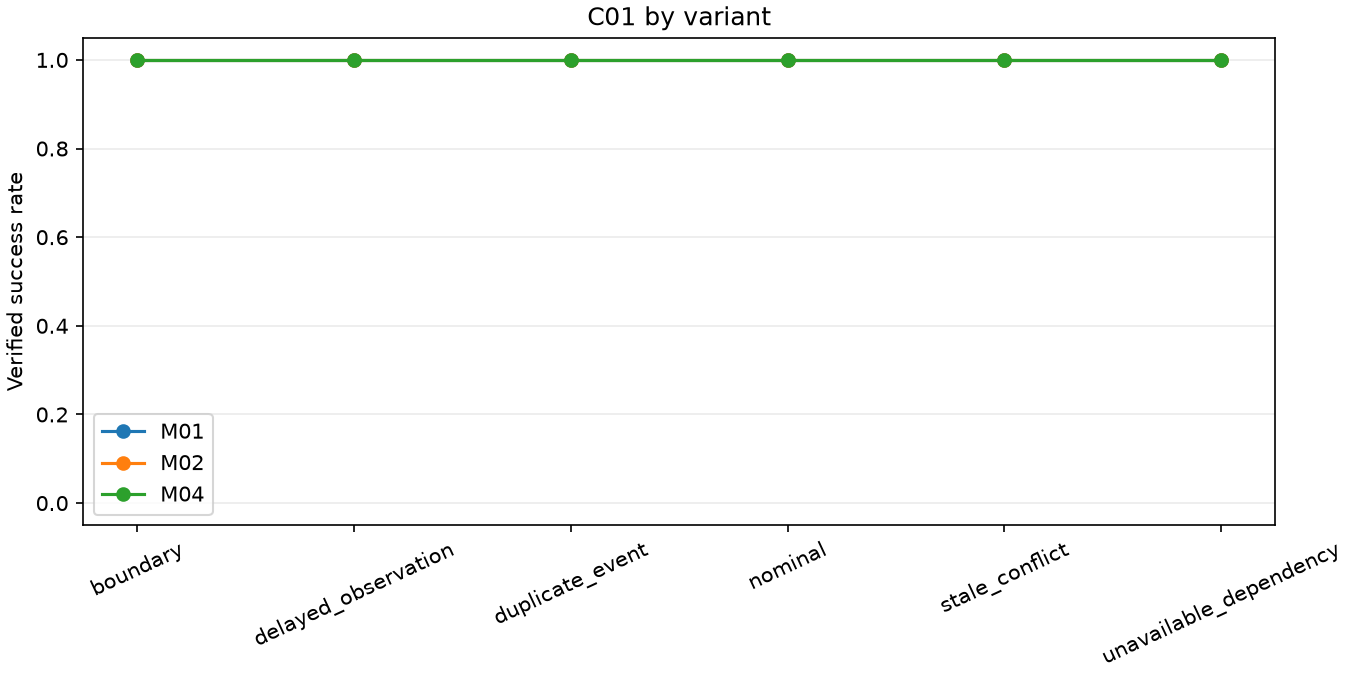

In [4]:
# Each point summarizes the seeds from one case variant, not the full benchmark.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified success rate")
ax.set_title(sample_case + " by variant")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### guarded event control · L3 | Build the first executable policy

In level 3, construct policy M01 for guarded event control with the public factory and keep its observation contract unchanged before sampling C01.

Chart 1, lesson level 3, summarizes guard admission and terminal task completion for C01.

In [5]:
# Construct the first released policy through the public factory.
primary_id = 'M01'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### guarded event control · L3 | Execute the primary method on the named case

Within this guarded event control comparison (C01), the guarded event control evaluator runs M01 on C01 and derives success from the independent task postcondition, not from a replayed trace.

In [6]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### guarded event control · L3 | Construct an independent comparison policy

For the guarded event control comparator run on C01, create M02 as a fresh object so recurrent state from M01 cannot leak into the matched comparison.

In [7]:
# Create a fresh policy object for the matched comparison.
secondary_id = 'M02'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M02


### guarded event control · L3 | Run the comparison under identical conditions

This level 3 comparison runs M02 on the same C01, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.

In [8]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### guarded event control · L3 | Aggregate the two executed episodes

Within this guarded event control comparison (C01), the package aggregator summarizes two executed guarded event control episodes, and cross-family claims still require the complete benchmark below.

In [9]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### guarded event control · L3 | Fresh policy outcomes

In the matched guarded event control comparison on C01, the next plot is computed from the guarded event control episode results just executed for C01 rather than copied from a frozen artifact.

## Comparison
The comparison is framed against typed fast decisions, arbitration between model-free and model-based control, and asynchronous code-plus-language-model agents.

This 01 fast event control lesson, interprets only its declared software case and seed. For the guarded event control comparator run on C01, the executed policy's score does not grant authority: For the guarded event control comparator run on C01, an independent environment check determines whether the requested postcondition was met. In the matched guarded event control comparison on C01, A measured latency belongs beside the outcome because extra computation can increase cost without preventing failure. For the guarded event control comparator run on C01, when two methods are compared, hold case, variant, seed, tool permissions, and success criteria constant. For the guarded event control comparator run on C01, this constraint matters especially when a planner returns plausible text that has not yet produced a verified effect. Missing runs remain missing evidence; In the matched guarded event control comparison on C01, failures and cancellations stay in their original denominators. For the guarded event control comparator run on C01, the example supports a reproducible statement about the recorded protocol, not a universal claim about unfamiliar tools, repositories, or users. For the guarded event control comparator run on C01, readers can change the case or seed and observe where the inference stops applying.

For 01 fast event control begin by distinguishing policy preference from action authority. For the guarded event control comparator run on C01, the method runs only over the candidate set supplied by the declared environment, and the environment's independent postcondition decides whether the task succeeded. In this 01 fast event control example, inspect the episode result together with decision latency; For the guarded event control comparator run on C01, A lower latency cannot compensate for a failed postcondition, and a higher cost is not evidence of better reasoning. For the guarded event control comparator run on C01, if this lesson compares methods, keep task family, variant, seed, input evidence, and permissions matched so that the observed difference has a clear interpretation. The 01 fast event control measurements cover the recorded software tasks and their frozen protocol. For the guarded event control comparator run on C01, they do not establish reliability on arbitrary repositories, novel tools, changing services, or real users. Within this guarded event control comparison (C01), use the computed values below to answer the notebook question, then check the trace identity and artifact digest before extending the conclusion. This makes the 01 fast event control exercise reproducible and keeps failure, cancellation, and missing evidence visible instead of silently turning them into success.



### guarded event control · L3 | Execute the XGBoost reference on matched conditions

This level 3 guarded event control reference call executes M04 on C01 with the same nominal seed as the fresh policies, and its score and time form one matched observation.

In [10]:
# Execute the measured XGBoost policy on the identical case specification.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Reference-policy runs:", 1)
print("XGBoost task success:", state_art_result["metrics"]["task_success"])


Reference-policy runs: 1
XGBoost task success: 1


### guarded event control · L3 | Recorded controller time

the guarded event control timing chart uses hash-verified frozen records for M01 and M04 on C01, not machine-dependent timings from fresh episodes. This level 3 guarded event control view describes the recorded environment under its declared case, variant and seed.

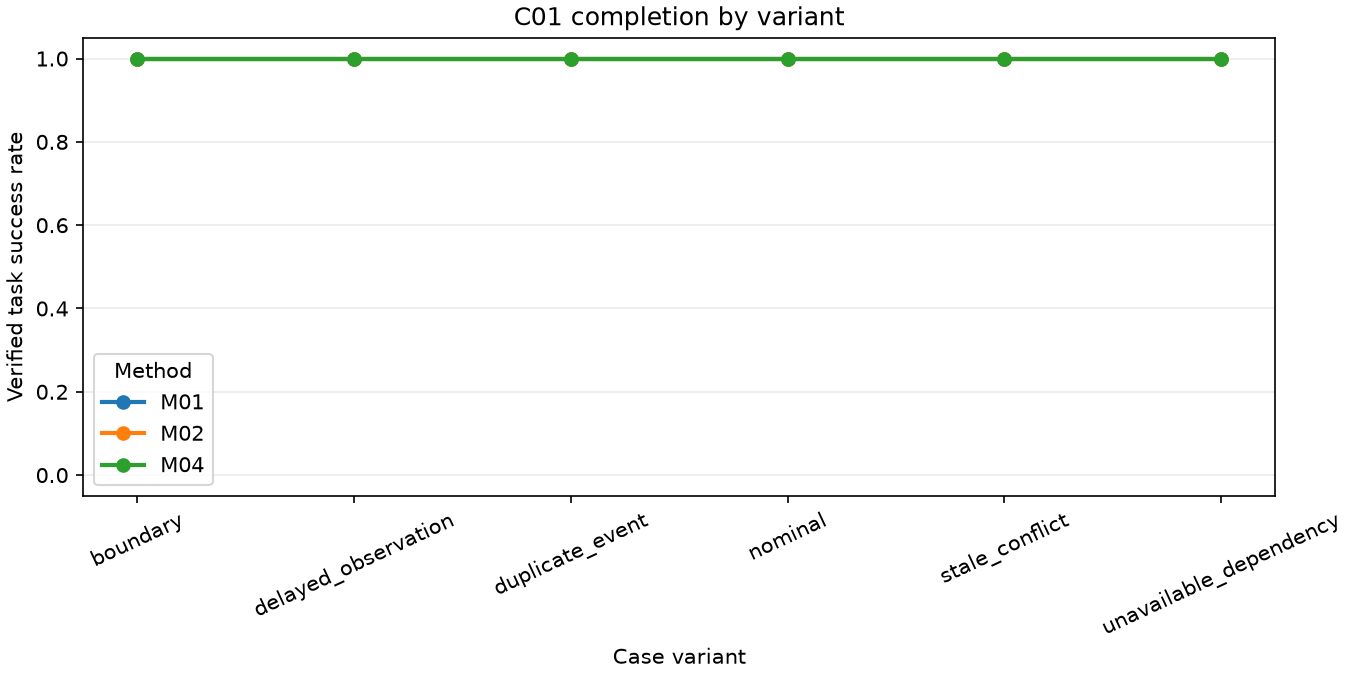

In [11]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified task success rate")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + " completion by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if False else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


In the matched guarded event control comparison on C01, for guarded event control, these bars show fresh task-postcondition outcomes for M01 and M02 on C01, with success encoded as 1 and failure as 0; Read the case and seed before comparing them. In the matched guarded event control comparison on C01, this controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks;

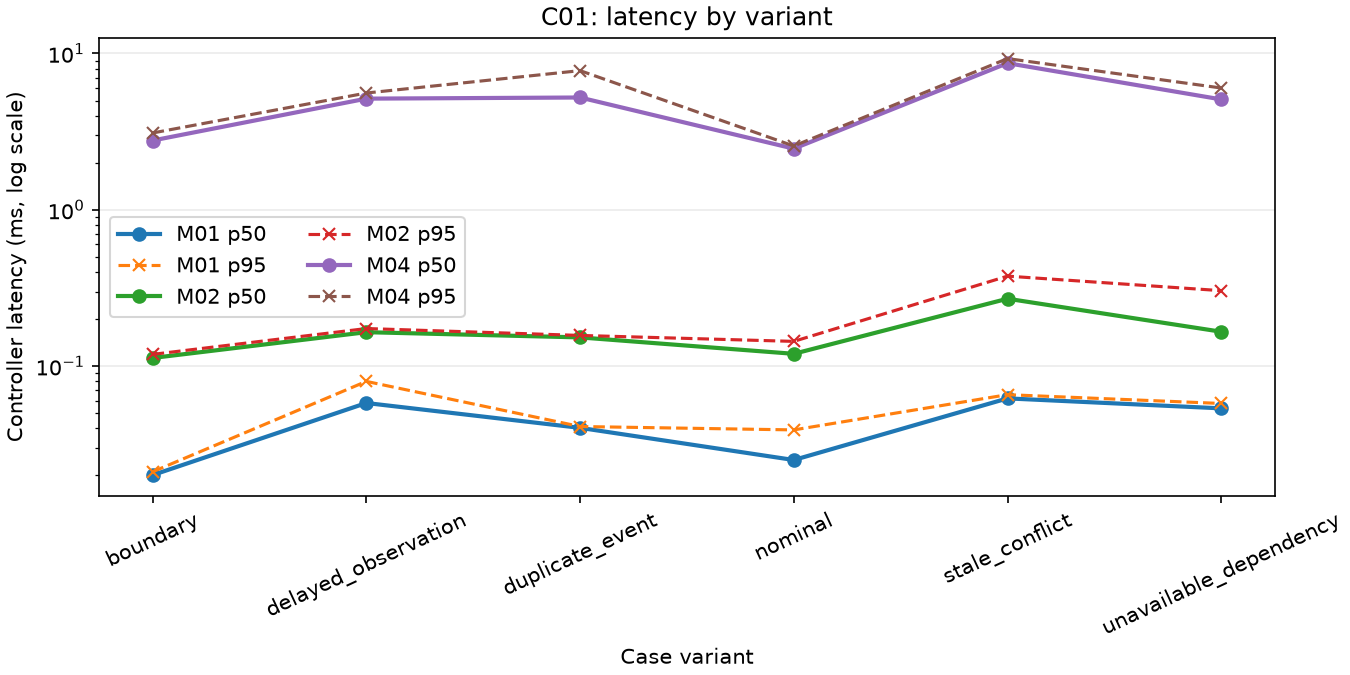

In [12]:
# Compare median and upper-tail controller time across the same case variants.
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
variants = sorted({variant for _, variant in case_records})
methods_to_plot = list(dict.fromkeys(selected_methods + ['M04']))
for method_id in methods_to_plot:
    p50, p95 = [], []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        values = sorted(e['metrics']['controller_ms'] for e in episodes)
        p50.append(values[(len(values) - 1) // 2] if values else float('nan'))
        p95.append(values[min(len(values) - 1, int(.95 * (len(values) - 1)))] if values else float('nan'))
    ax.plot(variants, p50, marker='o', linewidth=2, label=f'{method_id} p50')
    ax.plot(variants, p95, marker='x', linestyle='--', label=f'{method_id} p95')
ax.set_yscale('log')
ax.set_ylabel("Controller latency (ms, log scale)")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + ": latency by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(ncol=2)
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 3 guarded event control chart reads canonical M01/M04 records for C01, nominal variant and seed 40000 after the data boundary verifies their hashes.

Chart 3, lesson level 3, summarizes decision-time percentiles across the event variants for C01. The observation is bounded to this case.

## Results

**Answer:** The guarded event control level-3 comparison contains 2 fresh policy episodes plus 1 XGBoost M04 comparator on C01; those 3 matched runs do not establish population-level superiority for guarded event control.

In the matched guarded event control comparison on C01, this package replay checks one exact guarded decision on the same frozen observation; For the guarded event control comparator run on C01, it does not demonstrate general transfer, a biological mechanism, or superiority over a matched deployed system;

## Summary

Compare admissibility and terminal state before treating equal completion rates as equivalent control.




## References
- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev) - [LEE](https://doi.org/10.1016/j.neuron.2013.11.028) - [DPT](https://aclanthology.org/2025.acl-long.206/)